# 04 · Quantum teleportation

**Goal:** Alice has an unknown qubit $|\psi\rangle = \alpha|0\rangle + \beta|1\rangle$ and wants Bob to have it.
She can't measure it to learn $\alpha,\beta$ (measuring destroys it), and she can't copy it (the
no-cloning theorem). What she can use:

* a **Bell pair** shared with Bob in advance (one qubit each), and
* **2 classical bits** sent over an ordinary channel.

**Protocol:**
1. Alice and Bob share $|\Phi^+\rangle$ (q1 = Alice's half, q2 = Bob's half).
2. Alice does a **Bell measurement** on $|\psi\rangle$ (q0) together with her half (q1): `CNOT q0→q1`, then `H q0`, then measure both.
3. Bob's qubit is now $X^{m_x} Z^{m_z}|\psi\rangle$, i.e. $|\psi\rangle$ with up to two known errors.
   Alice sends him $(m_z, m_x)$ and he undoes them: apply `X` if $m_x = 1$, then `Z` if $m_z = 1$.

Nothing travels faster than light. Until Bob gets the two classical bits, his qubit looks completely random to him.

**How we check it:** after teleporting, apply the *inverse* of the preparation to Bob's qubit.
If he really holds $|\psi\rangle$, that returns it to $|0\rangle$, and we should measure `0` on **100%** of shots.

In [1]:
import numpy as np
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister, transpile
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator

sim = AerSimulator()   # supports mid-circuit measurement + classical feed-forward (dynamic circuits)
SHOTS = 4096

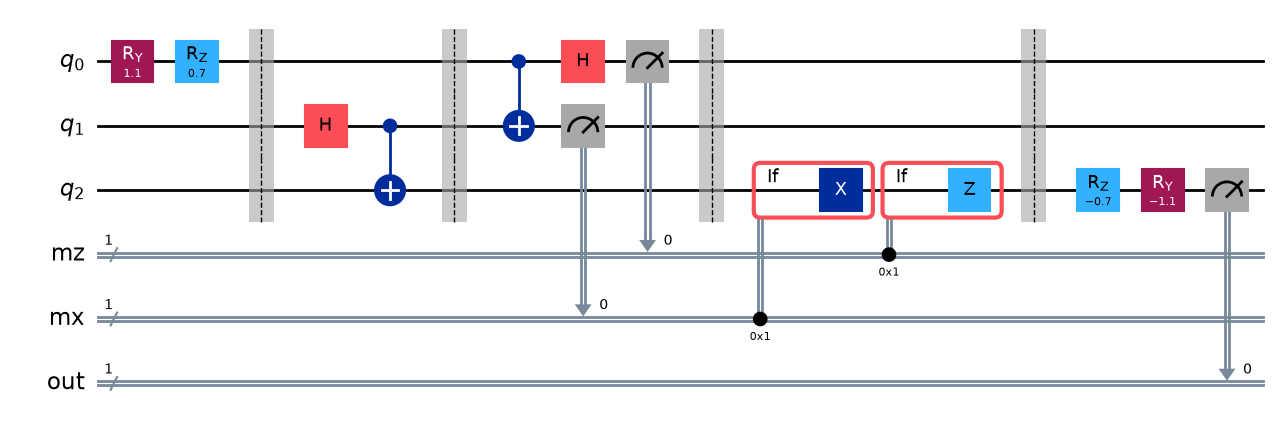

In [2]:
def teleport(theta, phi, corrections=True):
    q = QuantumRegister(3, "q")         # q0 = |psi> (Alice), q1 = Alice's half, q2 = Bob's half
    mz = ClassicalRegister(1, "mz")     # Alice's measurement of q0 -> decides Bob's Z correction
    mx = ClassicalRegister(1, "mx")     # Alice's measurement of q1 -> decides Bob's X correction
    out = ClassicalRegister(1, "out")   # final check on Bob's qubit
    qc = QuantumCircuit(q, mz, mx, out)

    # 0) Prepare an arbitrary state |psi> = RZ(phi) RY(theta) |0> on q0. Alice doesn't know theta/phi.
    qc.ry(theta, 0)
    qc.rz(phi, 0)
    qc.barrier()

    # 1) Shared Bell pair between q1 and q2 (same as notebook 01)
    qc.h(1)
    qc.cx(1, 2)
    qc.barrier()

    # 2) Alice's Bell measurement: rotate the Bell basis {q0,q1} into the computational basis, then measure
    qc.cx(0, 1)      # entangle |psi> with her half of the pair
    qc.h(0)          # move q0's phase information into a bit value
    qc.measure(0, mz)
    qc.measure(1, mx)
    qc.barrier()

    # 3) Bob's corrections, conditioned on the 2 classical bits (classical feed-forward)
    if corrections:
        with qc.if_test((mx, 1)):
            qc.x(2)  # undo the bit flip
        with qc.if_test((mz, 1)):
            qc.z(2)  # undo the phase flip
    qc.barrier()

    # 4) Verification: undo the preparation on Bob's qubit. It should be exactly |0> now.
    qc.rz(-phi, 2)
    qc.ry(-theta, 2)
    qc.measure(2, out)
    return qc

qc = teleport(theta=1.1, phi=0.7)
qc.draw("mpl", fold=-1)

In [3]:
def split_counts(counts):
    """Qiskit prints multi-register keys as 'out mx mz' (last-added register first)."""
    alice, bob0 = {}, 0
    for key, c in counts.items():
        out, mx, mz = key.split()
        alice[mz + mx] = alice.get(mz + mx, 0) + c
        bob0 += c if out == "0" else 0
    return alice, bob0 / sum(counts.values())

counts = sim.run(transpile(qc, sim), shots=SHOTS).result().get_counts()
alice, p0 = split_counts(counts)
print(f"Bob's qubit returned to |0>: {p0:.1%} of shots")
print("Alice's (mz mx) outcomes:", alice, " <- uniform: they reveal nothing about psi")

Bob's qubit returned to |0>: 100.0% of shots
Alice's (mz mx) outcomes: {'11': 974, '01': 1004, '00': 1066, '10': 1052}  <- uniform: they reveal nothing about psi


**Control experiment:** skip Bob's corrections. His qubit is only exactly $|\psi\rangle$ when Alice happened to measure `00` (25% of the time). In the other cases it's a wrong state that still sometimes passes the check by chance, so the pass rate drops well below 100%:

In [4]:
counts_nc = sim.run(transpile(teleport(1.1, 0.7, corrections=False), sim), shots=SHOTS).result().get_counts()
print(f"without corrections: Bob's qubit == psi check passes {split_counts(counts_nc)[1]:.1%} of shots")

without corrections: Bob's qubit == psi check passes 50.4% of shots


**Random states:** teleportation works for *any* input, not just the one we picked:

In [5]:
rng = np.random.default_rng(7)
for _ in range(5):
    theta, phi = rng.uniform(0, np.pi), rng.uniform(0, 2 * np.pi)
    c = sim.run(transpile(teleport(theta, phi), sim), shots=1024).result().get_counts()
    print(f"theta={theta:.2f} phi={phi:.2f} -> fidelity check {split_counts(c)[1]:.1%}")

theta=1.96 phi=5.64 -> fidelity check 100.0%
theta=2.44 phi=1.42 -> fidelity check 100.0%


theta=0.94 phi=5.49 -> fidelity check 100.0%


theta=0.02 phi=5.16 -> fidelity check 100.0%


theta=2.50 phi=2.94 -> fidelity check 100.0%
